# Coup-Proofing via Capital Relocation

PPOL 6805 / DSAN 6750: GIS for Spatial Data Science

Jeff Jacobs (Georgetown University)

## Introduction

Several previous studies have found robust relationships between spatial properties of a country’s **capital city** and that country’s propensity for ethnic and political **conflict** and **“instability”**.

Perceptions of this linkage also have an effect on “coup-proofing” decisions made by national governments. A recent BBC interview with Equatorial Guinea’s President Teodoro Obiang, for example, highlighted this as a factor behind his decision to relocate the capital city:

> It’s the remoteness of Oyala that makes it so appealing to President Obiang. In a rare interview he described how rebels had recently plotted a seaborne assault on his palace in the current capital, Malabo. ‘We need a secure place for my government and for future governments. That’s why we have created Oyala, to guarantee the government of Equatorial Guinea.’ ([Sackur 2012](#ref-sackur_equatorial_2012))

This case is far from exceptional, as an even more recent *Washington Post* article points out with respect to Myanmar’s decision to move its capital from Yangon to Naypyidaw:

> Analysts have described the decision as motivated by a desire to secure the military’s seat of power from any threat of protests or invasions. ([Berger 2021](#ref-berger_myanmars_2021))

Most of these studies, however, are based on observations of **conflict events**. In this study, we study the more fundamental variable of a capital’s distance from the **population centroid** of the country.

## Literature Review

Campante, Do, and Guimaraes ([2019](#ref-campante_capital_2019)) analyzes the relationship between the distance to a **capital city** and the **appearance of conflict** in a given country. Their two key findings are that:

> Conflict is more likely to emerge (and dislodge incumbents) closer to the capital

and

> Isolated capitals are associated with misgovernance.

This first finding is illustrated in <a href="#fig-conflict-dist" class="quarto-xref">Figure 1</a>.

<figure id="fig-conflict-dist">

<figcaption>Figure 1: The “core” finding in <span class="citation" data-cites="campante_capital_2019">Campante, Do, and Guimaraes (<a href="#ref-campante_capital_2019" role="doc-biblioref">2019</a>)</span>, where the probability of conflict decreases with distance from a national capital, and where this effect is <em>greater</em> for less-dense states.</figcaption>
</figure>

Within the political economy literature, a series of studies starting with Nunn and Puga ([2012](#ref-nunn_ruggedness_2012)) have shown how the effects of geospatial features like “terrain ruggedness” can differ wildly (e.g., can flip signs) between African and non-African states due to the history of slave-raiding and its effect on societal levels of trust ([Nunn and Wantchekon 2011](#ref-nunn_slave_2011)). Herbst ([2000](#ref-herbst_states_2000)) thus “zooms in” specifically on the effect of capital-to-population distance on political instability within Sub-Saharan Africa.

This historically-informed focus on postcolonial state-building provides a more nuanced view, wherein the single independent variable (distance to national capital) used in studies like Campante, Do, and Guimaraes ([2019](#ref-campante_capital_2019)) is disaggregated into something like “distribution of major population centers relative to national capital”.

This disaggregation, in turn, allows **first-order** and **second-order** GIS measures to be used to define and test hypotheses about the relationship between geography and political instability. First, “population centers” are defined based on first-order **population intensity functions**: subregions whose mean population intensity is above a certain threshold are interpreted as potentially “rebellious” population centers, over which that the central government in the capital aims to maximize control[1]. The *difficulty* of exerting this control is then defined based on a second-order **pairwise correlation functions**, where greater average distances between *pairs* of population centers are hypothesized to cause greater instability.

As shown in <a href="#fig-5-2" class="quarto-xref">Figure 2</a>, for example, Herbst ([2000](#ref-herbst_states_2000)) classifies the Democratic Republic of the Congo as a state with “difficult” population density based on these criteria, since the **capital** and largest city (Kinshasa) in the far west of the country is extremely distant from the next two largest cities (Mbuji-Mayi near the direct center and Lubumbashi in the far southeast). In contrast, Benin’s population density is classified as “favorable”, as density decreases with almost perfect exponential decay per increase in distance from the capital (Porto-Novo) and largest city (Cotonou), both in the far south of the country.

<table>
<colgroup>
<col style="width: 50%" />
<col style="width: 50%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="50.0%" data-layout-align="center">
<figure id="fig-5-2">

<figcaption>Figure 2: Example countries with population distributions classified as “favorable” (with respect to centralized state power and stability) in <span class="citation" data-cites="herbst_states_2000">Herbst (<a href="#ref-herbst_states_2000" role="doc-biblioref">2000</a>)</span></figcaption>
</figure>
</div></td>
<td style="text-align: center;"><div width="50.0%" data-layout-align="center">
<figure id="fig-5-4">

<figcaption>Figure 3: Example countries with population distributions classified as “difficult” (with respect to centralized state power and stability) in <span class="citation" data-cites="herbst_states_2000">Herbst (<a href="#ref-herbst_states_2000" role="doc-biblioref">2000</a>)</span></figcaption>
</figure>
</div></td>
</tr>
</tbody>
</table>

## Methodology

The **population centroids** we use herein might require some explanation, since the term “centroid” can be ambiguous. Here, we draw on the population centroid definition (along with the data) used in Hall et al. ([2019](#ref-hall_population_2019)).

## Exploratory Data Analysis (EDA)

Here we plot the base GIS objects we’re analyzing: the location of each **capital city** (in purple) and each **population centroid** (in yellow).

[1] Sociologically, Herbst ([2000](#ref-herbst_states_2000)) thus follows the “Weberian” definition of the state, as the entity possessing a monopoly over the legally-legitimized use of violence over a certain territory ([Weber 1919](#ref-weber_vocation_1919)).

In [ ]:
library(tidyverse) |> suppressPackageStartupMessages()
library(sf) |> suppressPackageStartupMessages()
library(mapview) |> suppressPackageStartupMessages()
# Fixes "API Key Required" message
mapviewOptions(basemaps = c("Esri.WorldGrayCanvas","Stadia.AlidadeSmoothDark","OpenStreetMap", "Esri.WorldImagery", "OpenTopoMap"))
library(units) |> suppressPackageStartupMessages()
cb_palette <- c("#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7")

In [ ]:
merged_long_sf <- readRDS("data/merged_long_sf.rds")
mapview(merged_long_sf, zcol="name", cex=4, label="geounit")

Warning in validateCoords(lng, lat, funcName): Data contains 3 rows with either
missing or invalid lat/lon values and will be ignored

We then construct an **area-normalized** measure of capital-centroid distance $\text{dist}^{\textsf{AN}}$, using the formula

$$
\text{dist}^{\textsf{AN}}_i = \text{dist}_i / \sqrt{\text{area}_i}.
$$

A plot of this measure by country looks as follows:

In [ ]:
merged_area_sf <- readRDS("data/merged_area_sf.rds")
# Uncomment to export to geojson
# merged_area_sf |> st_write("data/merged_area_sf.geojson")
mapview(merged_area_sf, zcol="scaled_dist")

If the data was too big for `mapview`, the following is the same map hosted on ArcGIS and embedded here:

<arcgis-embedded-map style="height:600px;width:100%;" item-id="138b4cf3f5e54863bd76d97b515124b1" theme="light" heading-enabled legend-enabled share-enabled center="12.539048194882033,32.107397539485724"scale="147914381.8978885" portal-url="https://georgetownuniv.maps.arcgis.com"></arcgis-embedded-map>

## Hypothesis Testing (Regression)

In [ ]:
merged_sub_sf <- readRDS("data/merged_sub_sf.rds")
merged_sub_sf |> head()

(`stat_smooth()`).

ℹ This can happen when ggplot fails to infer the correct grouping structure in
  the data.
ℹ Did you forget to specify a `group` aesthetic or to convert a numerical
  variable into a factor?

(`geom_point()`).

(`geom_text()`).

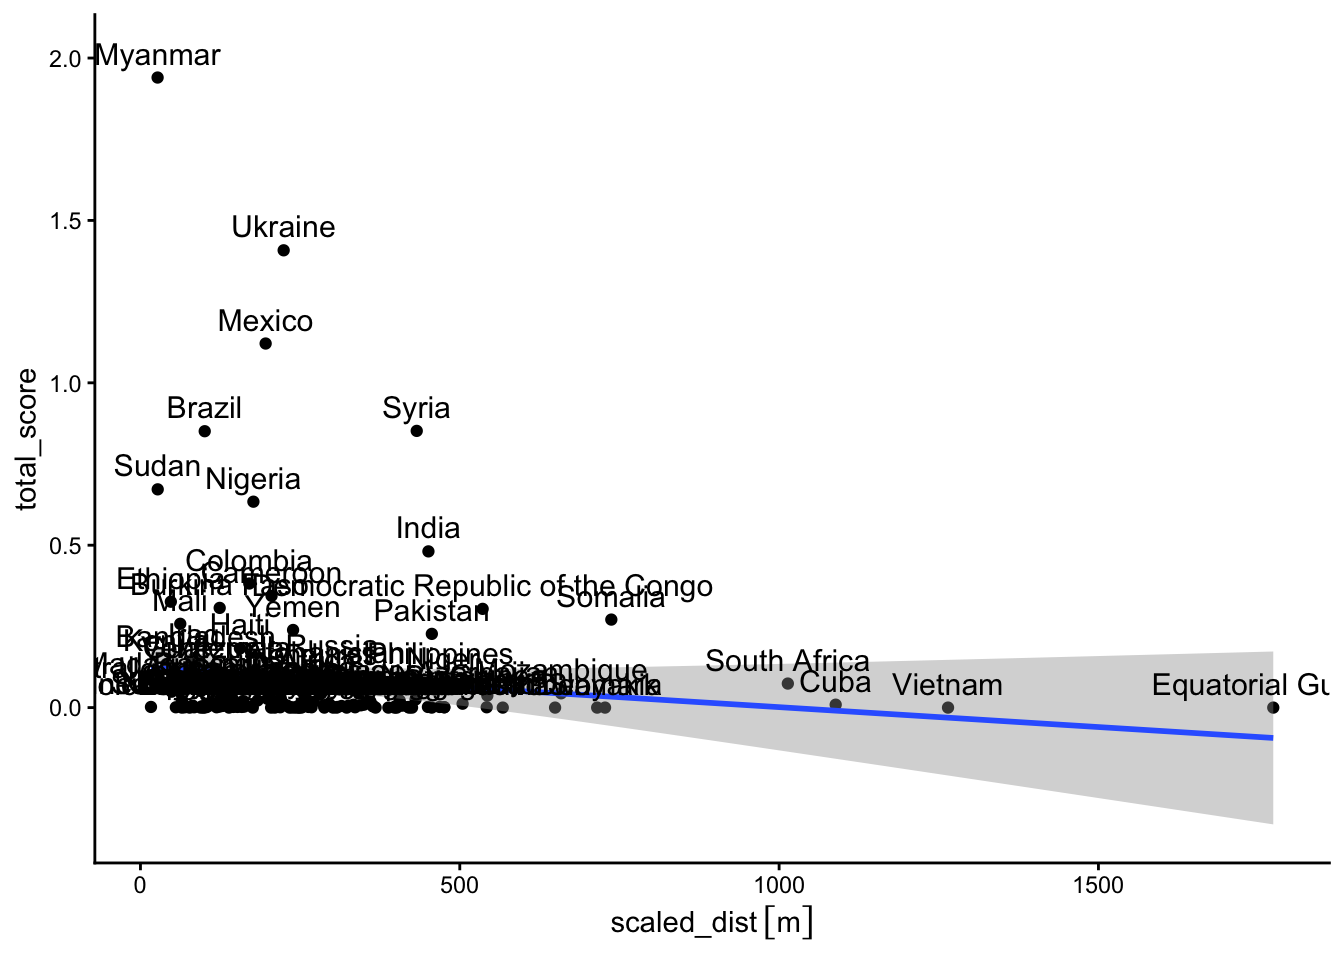

In [ ]:
merged_sub_sf |> ggplot(aes(x=scaled_dist, y=total_score, label=NAME_ENGLI)) +
  geom_point() +
  geom_smooth(method='lm', formula= y~x) +
  geom_text(size=4, nudge_y = 0.075) +
  theme_classic()

## Discussion

## Conclusion

Our evidence indicates that the spatial dynamics of **conflict** differ from the spatial dynamics of **misgovernance**.

Berger, Miriam. 2021. “[Myanmar’s Military Built a New Capital as a Haven for Power. Other Countries Have Tried That, Too.](https://www.washingtonpost.com/world/2021/02/06/myanmars-military-built-new-capital-haven-power-other-countries-have-tried-that-too/)” *Washington Post*, February 6, 2021.

Campante, Filipe R., Quoc-Anh Do, and Bernardo Guimaraes. 2019. “[Capital Cities, Conflict, and Misgovernance](https://doi.org/10.1257/app.20170111).” *American Economic Journal: Applied Economics* 11 (3): 298–337.

Hall, Ola, Maria Francisca Archila Bustos, Niklas Boke Olén, and Thomas Niedomysl. 2019. “[Population Centroids of the World Administrative Units from Nighttime Lights 1992-2013](https://doi.org/10.1038/s41597-019-0250-z).” *Scientific Data* 6 (1): 235.

Herbst, Jeffrey. 2000. *[States and Power in Africa: Comparative Lessons in Authority and Control - Second Edition](https://books.google.com?id=0xbsEAAAQBAJ)*. Princeton University Press.

Nunn, Nathan, and Diego Puga. 2012. “[Ruggedness: The Blessing of Bad Geography in Africa](https://www.jstor.org/stable/41349158).” *The Review of Economics and Statistics* 94 (1): 20–36.

Nunn, Nathan, and Leonard Wantchekon. 2011. “[The Slave Trade and the Origins of Mistrust in Africa](https://doi.org/10.1257/aer.101.7.3221).” *American Economic Review* 101 (7): 3221–52.

Sackur, Stephen. 2012. “[Equatorial Guinea: Obiang’s Future Capital, Oyala](https://www.bbc.com/news/magazine-20731448).” *BBC News: Magazine*, December 14, 2012.

Weber, Max. 1919. *[The Vocation Lectures](https://books.google.com?id=V6t5EAAAQBAJ)*. Hackett Publishing.